# Expt 7: Simple Autoencoder for Dimensionality Reduction and Feature Learning


 Name : Swathi
 Roll No: 24BAD122


## Aim
To implement and train a simple Autoencoder that compresses input data into a lower-dimensional representation and reconstructs the original data from the learned features.

## Part A: Dataset Preparation

In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split

tf.random.set_seed(42)
np.random.seed(42)
print("swathi  24BAD122")

swathi  24BAD122


In [2]:
# Load MNIST (already split into train/test)
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print("x_train shape:", x_train.shape, "| dtype:", x_train.dtype)
print("x_test shape :", x_test.shape,  "| dtype:", x_test.dtype)
print("Pixel range  :", x_train.min(), "-", x_train.max())

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
x_train shape: (60000, 28, 28) | dtype: uint8
x_test shape : (10000, 28, 28) | dtype: uint8
Pixel range  : 0 - 255


In [4]:
# Normalize to [0, 1]
x_train = x_train.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

# Flatten 28x28 -> 784 for a Dense autoencoder
x_train_flat = x_train.reshape(len(x_train), -1)
x_test_flat  = x_test.reshape(len(x_test), -1)

# Hold out part of the training data for validation
x_tr, x_val = train_test_split(x_train_flat, test_size=0.1, random_state=42)

print("Train:", x_tr.shape, "Validation:", x_val.shape, "Test:", x_test_flat.shape)
# For an autoencoder, input == target

Train: (54000, 784) Validation: (6000, 784) Test: (10000, 784)


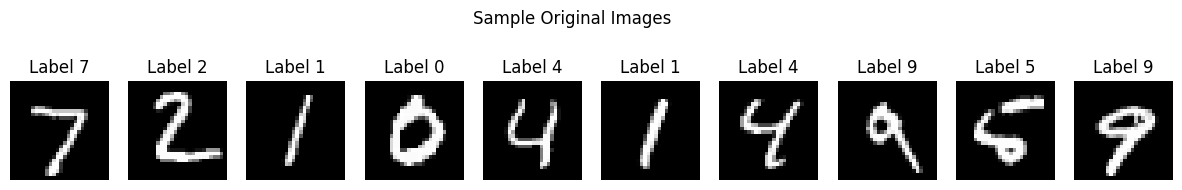

In [5]:
# Display sample original images
n = 10
plt.figure(figsize=(15, 2))
for i in range(n):
    ax = plt.subplot(1, n, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    plt.title(f"Label {y_test[i]}")
    plt.axis("off")
plt.suptitle("Sample Original Images", y=1.1)
plt.show()

## Part B: Implementing the Autoencoder Model

In [6]:

input_dim  = 784   # 28 x 28
latent_dim = 32    # bottleneck size (compression ratio ~ 24.5x)

# Encoder
input_img = keras.Input(shape=(input_dim,), name="input")
x = layers.Dense(256, activation="relu", name="enc_dense_1")(input_img)
x = layers.Dense(128, activation="relu", name="enc_dense_2")(x)
latent = layers.Dense(latent_dim, activation="relu", name="bottleneck")(x)

# Decoder
x = layers.Dense(128, activation="relu", name="dec_dense_1")(latent)
x = layers.Dense(256, activation="relu", name="dec_dense_2")(x)
output = layers.Dense(input_dim, activation="sigmoid", name="output")(x)

# Full autoencoder
autoencoder = keras.Model(input_img, output, name="autoencoder")

# Separate encoder model (input -> latent)
encoder = keras.Model(input_img, latent, name="encoder")

# Separate decoder model (latent -> reconstruction), reusing trained layers
latent_input = keras.Input(shape=(latent_dim,), name="latent_input")
d = autoencoder.get_layer("dec_dense_1")(latent_input)
d = autoencoder.get_layer("dec_dense_2")(d)
d = autoencoder.get_layer("output")(d)
decoder = keras.Model(latent_input, d, name="decoder")

autoencoder.compile(optimizer="adam", loss="mse")
autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_dense_1 (Dense)             │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_dense_2 (Dense)             │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_dense_1 (Dense)             │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_dense_2 (Dense)             │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 784)            │       201,488 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 476,720 (1.82 MB)

 Trainable params: 476,720 (1.82 MB)

 Non-trainable params: 0 (0.00 B)

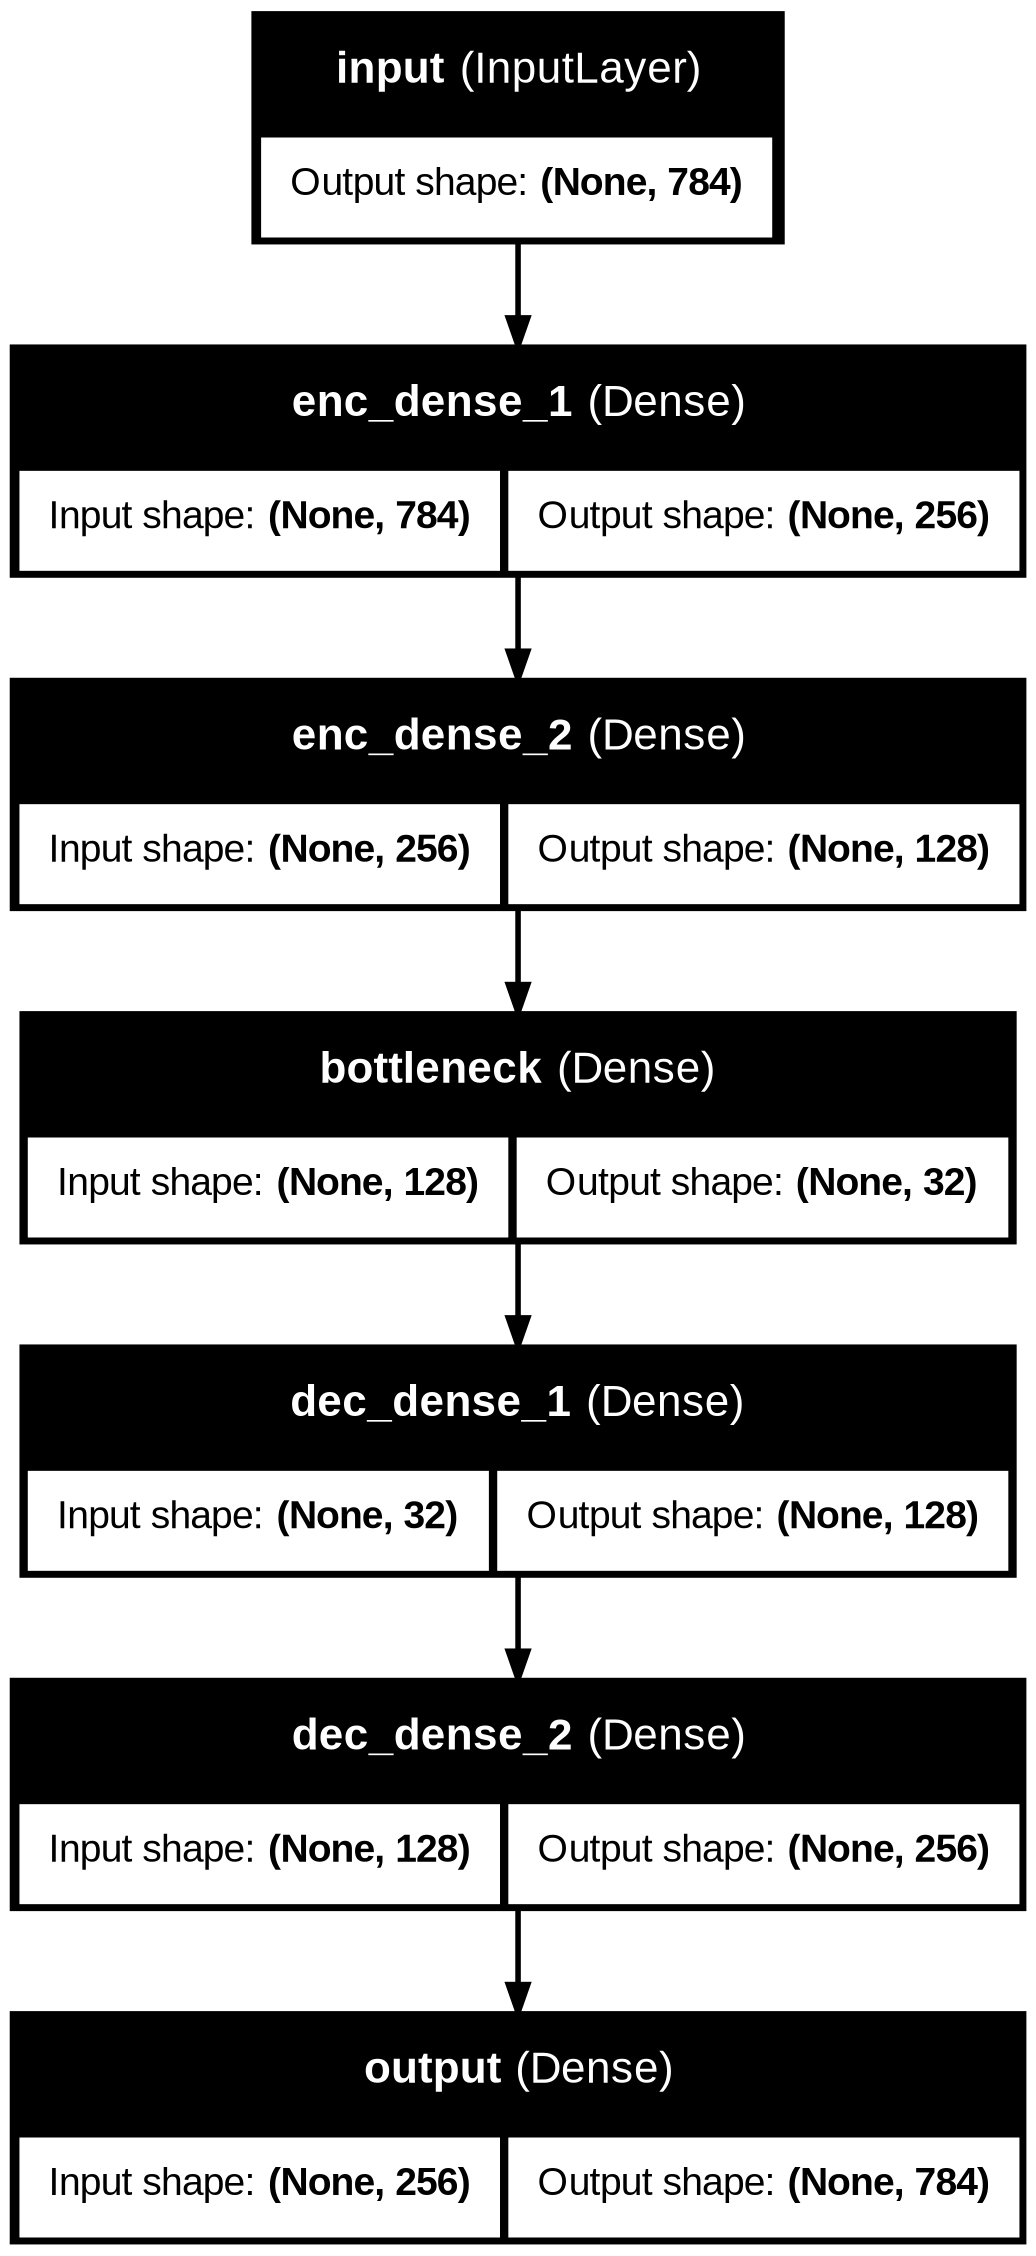

In [ ]:
keras.utils.plot_model(autoencoder, show_shapes=True, show_layer_names=True)


## Part C: Model Training and Performance Evaluation

In [ ]:
history = autoencoder.fit(
    x_tr, x_tr,                       # input = target
    epochs=30,
    batch_size=256,
    shuffle=True,
    validation_data=(x_val, x_val),
    verbose=1
)

Epoch 1/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - loss: 0.0611 - val_loss: 0.0354
Epoch 2/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 6s 29ms/step - loss: 0.0273 - val_loss: 0.0219
Epoch 3/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - loss: 0.0198 - val_loss: 0.0179
Epoch 4/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - loss: 0.0169 - val_loss: 0.0159
Epoch 5/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - loss: 0.0152 - val_loss: 0.0146
Epoch 6/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 8s 39ms/step - loss: 0.0140 - val_loss: 0.0137
Epoch 7/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 8s 36ms/step - loss: 0.0130 - val_loss: 0.0127
Epoch 8/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - loss: 0.0122 - val_loss: 0.0119
Epoch 9/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 9s 21ms/step - loss: 0.0115 - val_loss: 0.0113
Epoch 10/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 7s 28ms/step - loss: 0.0109 - val_loss: 0.0108
Epoch 11/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - loss: 0.0104 - val_loss: 0.0104
Epoch 12/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 

In [ ]:
# Record losses
print("Final training loss  :", history.history["loss"][-1])
print("Final validation loss:", history.history["val_loss"][-1])

# Test-set reconstruction MSE
test_mse = autoencoder.evaluate(x_test_flat, x_test_flat, verbose=0)
recon = autoencoder.predict(x_test_flat, verbose=0)
manual_mse = np.mean((x_test_flat - recon) ** 2)
print(f"Test reconstruction MSE (Keras)  : {test_mse:.6f}")
print(f"Test reconstruction MSE (manual) : {manual_mse:.6f}")

Final training loss  : 0.007265583612024784
Final validation loss: 0.007719304412603378
Test reconstruction MSE (Keras)  : 0.007438
Test reconstruction MSE (manual) : 0.007438


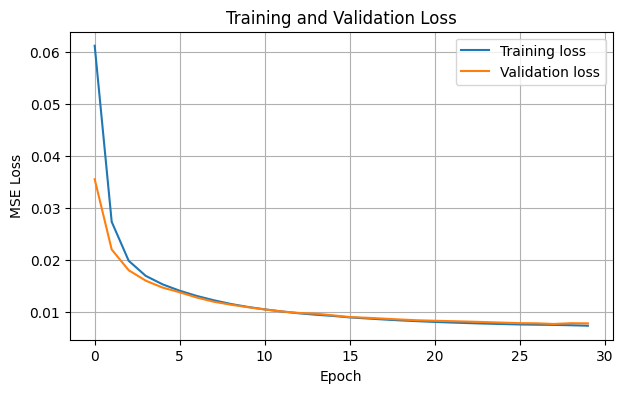

In [ ]:
# Plot training vs validation loss
plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("MSE Loss")
plt.title("Training and Validation Loss")
plt.legend(); plt.grid(True); plt.show()

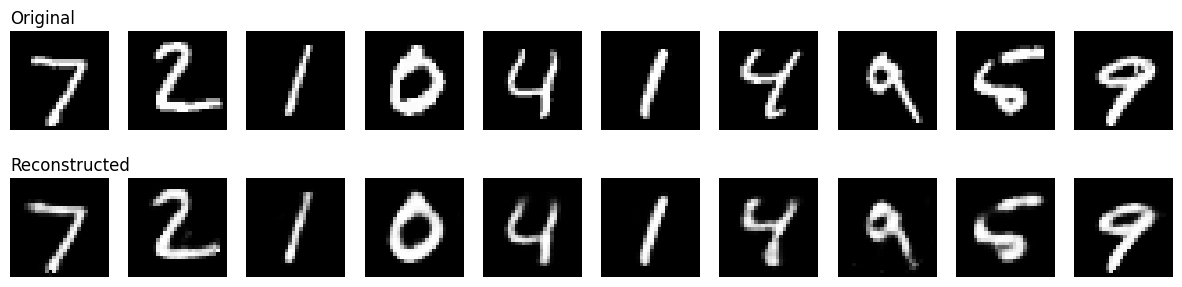

In [ ]:
# Original vs reconstructed
n = 10
plt.figure(figsize=(15, 3.5))
for i in range(n):
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i], cmap="gray"); plt.axis("off")
    if i == 0: ax.set_title("Original", loc="left")
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(recon[i].reshape(28, 28), cmap="gray"); plt.axis("off")
    if i == 0: ax.set_title("Reconstructed", loc="left")
plt.show()

## Part D: Dimensionality Reduction, Feature Visualization and Experiment Management

> **Note:** The lab sheet's first bullet in Part D ("Provide new movie-review sentences to the trained LSTM model") belongs to an earlier LSTM experiment and does not apply to an autoencoder. It is replaced here by feeding new/unseen **test images** to the trained autoencoder.

In [ ]:
# Latent representations of test samples
latent_test = encoder.predict(x_test_flat, verbose=0)

print("Original data shape  :", x_test_flat.shape)
print("Compressed data shape:", latent_test.shape)
print(f"Dimensionality reduced from {x_test_flat.shape[1]} to {latent_test.shape[1]} "
      f"({x_test_flat.shape[1]/latent_test.shape[1]:.1f}x compression)")

Original data shape  : (10000, 784)
Compressed data shape: (10000, 32)
Dimensionality reduced from 784 to 32 (24.5x compression)


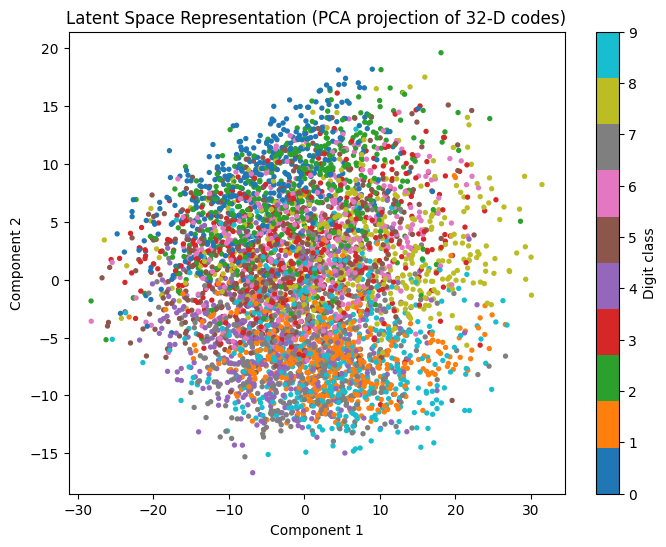

In [ ]:
# Visualize latent space in 2D (PCA on the 32-D latent codes)
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
latent_2d = pca.fit_transform(latent_test[:5000])

plt.figure(figsize=(8, 6))
sc = plt.scatter(latent_2d[:, 0], latent_2d[:, 1], c=y_test[:5000], cmap="tab10", s=8)
plt.colorbar(sc, label="Digit class")
plt.title("Latent Space Representation (PCA projection of 32-D codes)")
plt.xlabel("Component 1"); plt.ylabel("Component 2")
plt.show()

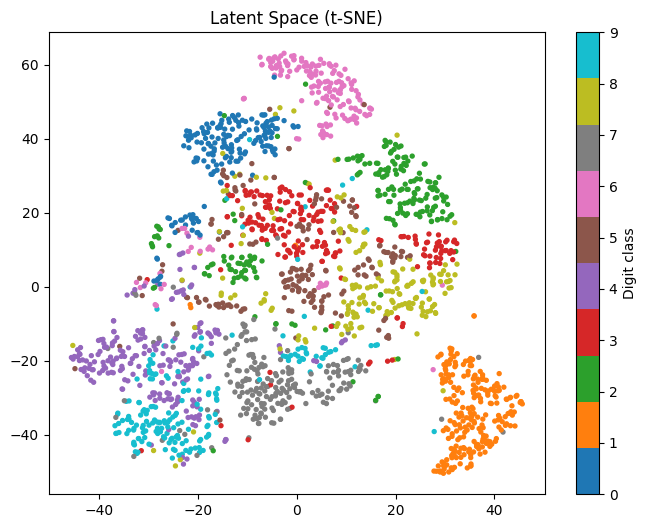

In [ ]:
# Optional: t-SNE for a clearer view of clusters
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, random_state=42, init="pca", learning_rate="auto")
latent_tsne = tsne.fit_transform(latent_test[:2000])

plt.figure(figsize=(8, 6))
sc = plt.scatter(latent_tsne[:, 0], latent_tsne[:, 1], c=y_test[:2000], cmap="tab10", s=8)
plt.colorbar(sc, label="Digit class")
plt.title("Latent Space (t-SNE)")
plt.show()

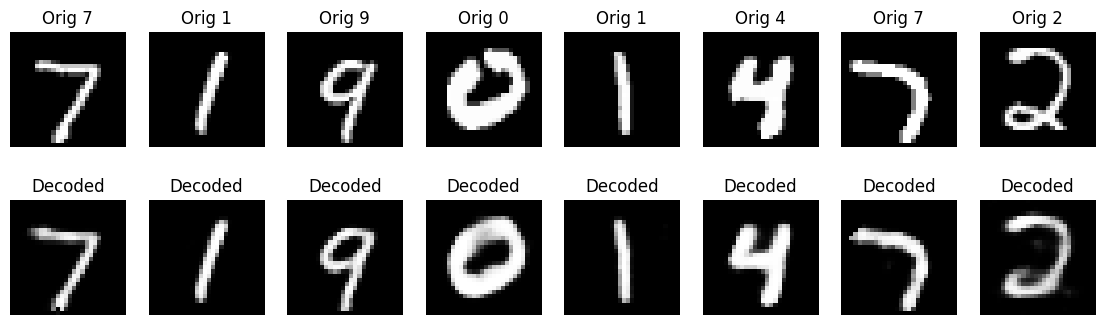

In [ ]:
# Reconstruct selected test samples using the Decoder
idx = [0, 5, 12, 25, 37, 48, 60, 72]
codes = encoder.predict(x_test_flat[idx], verbose=0)
decoded = decoder.predict(codes, verbose=0)

plt.figure(figsize=(14, 4))
for k, i in enumerate(idx):
    plt.subplot(2, len(idx), k + 1)
    plt.imshow(x_test[i], cmap="gray"); plt.axis("off"); plt.title(f"Orig {y_test[i]}")
    plt.subplot(2, len(idx), k + 1 + len(idx))
    plt.imshow(decoded[k].reshape(28, 28), cmap="gray"); plt.axis("off"); plt.title("Decoded")
plt.show()

In [ ]:
# Per-sample reconstruction error + comparison with plain PCA (baseline)
per_sample_mse = np.mean((x_test_flat - recon) ** 2, axis=1)
print("Mean per-sample MSE:", per_sample_mse.mean())

pca32 = PCA(n_components=latent_dim).fit(x_tr)
pca_recon = pca32.inverse_transform(pca32.transform(x_test_flat))
print(f"Autoencoder test MSE ({latent_dim}-D): {manual_mse:.6f}")
print(f"PCA test MSE         ({latent_dim}-D): {np.mean((x_test_flat - pca_recon)**2):.6f}")

Mean per-sample MSE: 0.007438301
Autoencoder test MSE (32-D): 0.007438
PCA test MSE         (32-D): 0.016831
